In [5]:
import pandas as pd

In [6]:
df = pd.read_csv("spam.csv", encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "text"]

print(df.shape)
print(df["label"].value_counts())
df.head()

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
# Missing values / duplicates
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

label    0
text     0
dtype: int64
Duplicates: 403


In [8]:
# Duplicates ain karanna
df = df.drop_duplicates().reset_index(drop=True)
print(df["label"].value_counts())

label
ham     4516
spam     653
Name: count, dtype: int64


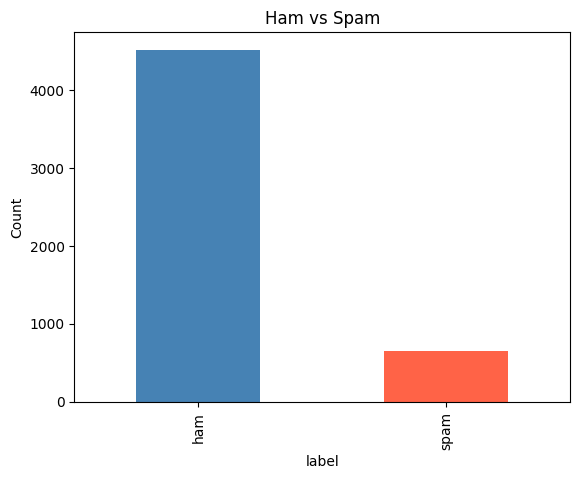

In [9]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Ham vs Spam")
plt.ylabel("Count")
plt.show()

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4516.0   70.459256  56.358207   2.0   34.0   52.0   90.0  910.0
spam    653.0  137.891271  30.137753  13.0  132.0  149.0  157.0  224.0


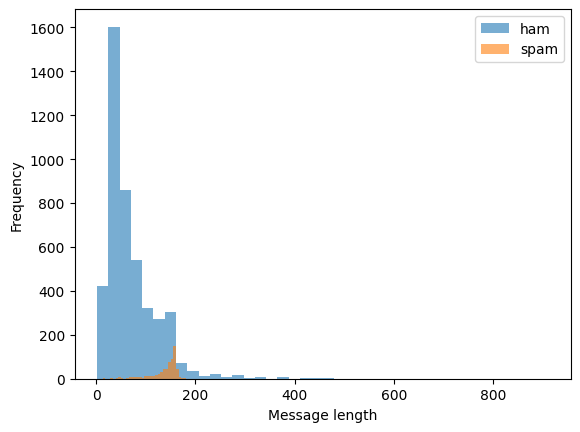

In [10]:
df["length"] = df["text"].apply(len)

print(df.groupby("label")["length"].describe())

df[df.label == "ham"]["length"].plot(kind="hist", bins=40, alpha=0.6, label="ham")
df[df.label == "spam"]["length"].plot(kind="hist", bins=40, alpha=0.6, label="spam")
plt.legend()
plt.xlabel("Message length")
plt.show()

In [11]:
from collections import Counter

spam_words = " ".join(df[df.label == "spam"]["text"]).lower().split()
print(Counter(spam_words).most_common(15))

[('to', 591), ('a', 328), ('call', 298), ('your', 241), ('you', 226), ('for', 182), ('the', 181), ('free', 157), ('or', 157), ('2', 151), ('is', 138), ('ur', 119), ('on', 118), ('from', 118), ('have', 115)]


In [12]:
ham_words = " ".join(df[df.label == "ham"]["text"]).lower().split()
print(Counter(ham_words).most_common(15))

[('i', 2063), ('you', 1606), ('to', 1464), ('the', 1042), ('a', 953), ('and', 815), ('u', 794), ('in', 726), ('my', 666), ('is', 628), ('me', 559), ('for', 471), ('of', 471), ('that', 430), ('it', 418)]


In [13]:
print(df.groupby("label")["length"].describe())

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4516.0   70.459256  56.358207   2.0   34.0   52.0   90.0  910.0
spam    653.0  137.891271  30.137753  13.0  132.0  149.0  157.0  224.0


In [14]:
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
print(df[["label", "label_num"]].head())

  label  label_num
0   ham          0
1   ham          0
2  spam          1
3   ham          0
4   ham          0


In [15]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print("Train spam %:", y_train.mean() * 100)
print("Test spam %:", y_test.mean() * 100)

Train: 4135 Test: 1034
Train spam %: 12.623941958887544
Test spam %: 12.669245647969053


In [16]:
import re

def clean_text(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " url ", t)   # links
    t = re.sub(r"\d+", " num ", t)               # numbers
    t = re.sub(r"[^a-z\s]", " ", t)              # punctuation
    t = re.sub(r"\s+", " ", t).strip()
    return t

print(clean_text(df["text"][2]))

free entry in num a wkly comp to win fa cup final tkts num st may num text fa to num to receive entry question std txt rate t c s apply num over num s


In [17]:
X_train_clean = X_train.apply(clean_text)
X_test_clean = X_test.apply(clean_text)

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)

X_train_tfidf = tfidf.fit_transform(X_train_clean)  # fit: train walin witharai
X_test_tfidf = tfidf.transform(X_test_clean)        # test: transform witharai

print("Train shape:", X_train_tfidf.shape)
print("Test shape:", X_test_tfidf.shape)
print("Sample words:", tfidf.get_feature_names_out()[:20])

Train shape: (4135, 5538)
Test shape: (1034, 5538)
Sample words: ['aah' 'aathi' 'abi' 'ability' 'abiola' 'able' 'able come' 'able deliver'
 'able num' 'able pay' 'abt' 'abt num' 'abt tht' 'abt ur' 'aburo'
 'aburo enjoy' 'ac' 'acc' 'accept' 'accept day']


In [19]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)

nb_pred = nb.predict(X_test_tfidf)
print("Naive Bayes accuracy:", (nb_pred == y_test).mean())

Naive Bayes accuracy: 0.97678916827853


In [20]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_tfidf, y_train)

lr_pred = lr.predict(X_test_tfidf)
print("Logistic Regression accuracy:", (lr_pred == y_test).mean())

Logistic Regression accuracy: 0.9709864603481625


In [21]:
from sklearn.metrics import classification_report

print("=== Naive Bayes ===")
print(classification_report(y_test, nb_pred, target_names=["ham", "spam"]))

print("=== Logistic Regression ===")
print(classification_report(y_test, lr_pred, target_names=["ham", "spam"]))

=== Naive Bayes ===
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       903
        spam       1.00      0.82      0.90       131

    accuracy                           0.98      1034
   macro avg       0.99      0.91      0.94      1034
weighted avg       0.98      0.98      0.98      1034

=== Logistic Regression ===
              precision    recall  f1-score   support

         ham       0.97      0.99      0.98       903
        spam       0.94      0.82      0.88       131

    accuracy                           0.97      1034
   macro avg       0.96      0.91      0.93      1034
weighted avg       0.97      0.97      0.97      1034



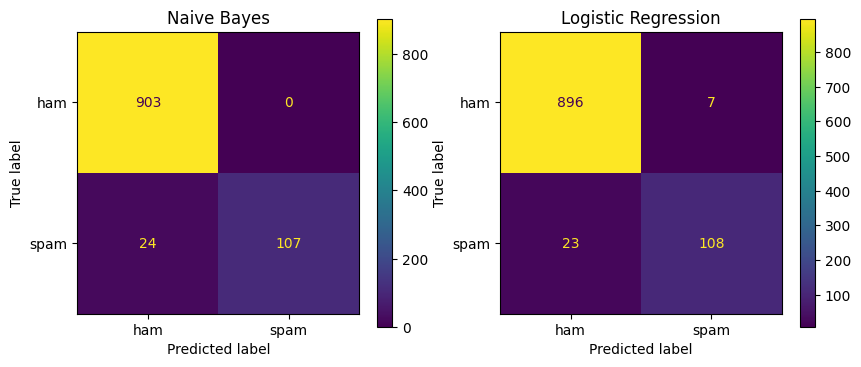

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, display_labels=["ham", "spam"], ax=axes[0])
axes[0].set_title("Naive Bayes")
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, display_labels=["ham", "spam"], ax=axes[1])
axes[1].set_title("Logistic Regression")
plt.show()

In [23]:
missed = X_test[(y_test == 1) & (nb_pred == 0)]
for m in missed.head(10):
    print("-", m)
    print()

- Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING now.

- Send a logo 2 ur lover - 2 names joined by a heart. Txt LOVE NAME1 NAME2 MOBNO eg LOVE ADAM EVE 07123456789 to 87077 Yahoo! POBox36504W45WQ TxtNO 4 no ads 150p.

- Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p 08712400603

- Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Callså£1/minMobsmoreLKPOBOX177HP51FL

- TheMob>Hit the link to get a premium Pink Panther game, the new no. 1 from Sugababes, a crazy Zebra animation or a badass Hoody wallpaper-all 4 FREE!

- Guess what! Somebody you know secretly fancies you! Wanna find out who it is? Give us a call on 09065394973 from Landline DATEBox1282EssexCM61XN 150p/min 18

- ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8E

In [24]:
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_bal.fit(X_train_tfidf, y_train)
print(classification_report(y_test, lr_bal.predict(X_test_tfidf), target_names=["ham", "spam"]))

              precision    recall  f1-score   support

         ham       0.99      0.97      0.98       903
        spam       0.84      0.95      0.89       131

    accuracy                           0.97      1034
   macro avg       0.92      0.96      0.94      1034
weighted avg       0.97      0.97      0.97      1034



In [25]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

probs = nb.predict_proba(X_test_tfidf)[:, 1]
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (probs >= t).astype(int)
    print(t, "precision:", round(precision_score(y_test, pred), 3),
             "recall:", round(recall_score(y_test, pred), 3))

0.5 precision: 1.0 recall: 0.817
0.4 precision: 0.991 recall: 0.863
0.3 precision: 0.983 recall: 0.901
0.2 precision: 0.961 recall: 0.947
0.1 precision: 0.726 recall: 0.969


In [26]:
from scipy.sparse import hstack, csr_matrix

def extra_features(texts):
    return csr_matrix(np.c_[
        texts.str.len() / 160,
        texts.str.count(r"\d") / 20,
        texts.apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1)),
        texts.str.contains(r"\d{9,}").astype(int),             # phone number
        texts.str.contains(r"£|å£|\d+p\b|pobox", case=False).astype(int)  # price / PO box
    ])

X_train_comb = hstack([X_train_tfidf, extra_features(X_train)])
X_test_comb = hstack([X_test_tfidf, extra_features(X_test)])

lr2 = LogisticRegression(max_iter=1000, class_weight="balanced")
lr2.fit(X_train_comb, y_train)
print(classification_report(y_test, lr2.predict(X_test_comb), target_names=["ham", "spam"]))

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.92      0.91      0.92       131

    accuracy                           0.98      1034
   macro avg       0.95      0.95      0.95      1034
weighted avg       0.98      0.98      0.98      1034



In [27]:
from sklearn.naive_bayes import MultinomialNB

# NB walata negative values baha, extra features 0-1 walata scale karala thiyenawa
nb2 = MultinomialNB()
nb2.fit(X_train_comb, y_train)
probs2 = nb2.predict_proba(X_test_comb)[:, 1]

for t in [0.5, 0.3, 0.2]:
    pred = (probs2 >= t).astype(int)
    print(t, "precision:", round(precision_score(y_test, pred), 3),
             "recall:", round(recall_score(y_test, pred), 3))

0.5 precision: 0.992 recall: 0.901
0.3 precision: 0.976 recall: 0.931
0.2 precision: 0.961 recall: 0.939


In [28]:
import joblib
joblib.dump(nb2, "spam_model.pkl")
joblib.dump(tfidf, "tfidf.pkl")

from google.colab import files
files.download("spam_model.pkl")
files.download("tfidf.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
from google.colab import files
files.download("tfidf.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>